# RQ3 Analysis: BM25 Semantic Relevance

Computes the BM25 semantic relevance scores of AI-generated PR descriptions compared to their human-written counterparts.

- Uses the `rank_bm25` package (BM25Okapi) and `nltk` for tokenization.
- Preprocessing: strips Markdown, removes punctuation, lowercases, and tokenizes using `word_tokenize`.
- Corpus: For each model/context group, the collection of Human Descriptions forms the BM25 corpus.
- Scores are min-max normalized to [0, 1] per model/context group for cross-group comparison.

In [1]:
import subprocess, sys
subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--quiet', 'rank-bm25'])

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from rank_bm25 import BM25Okapi
import nltk
from nltk.tokenize import word_tokenize
import re
import string
import os

nltk.download('punkt_tab', quiet=True)

True

In [2]:
# Set consistent plotting style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

## 1. Preprocessing

In [3]:
def preprocess_text(text: str) -> list[str]:
    """Strip Markdown, remove punctuation, lowercase, and tokenize."""
    if not isinstance(text, str) or not text.strip():
        return []

    # Strip Markdown: code blocks
    text = re.sub(r'```[\s\S]*?```', ' ', text)
    text = re.sub(r'`[^`]+`', ' ', text)
    # Strip Markdown: images ![alt](url)
    text = re.sub(r'!\[[^\]]*\]\([^)]*\)', ' ', text)
    # Strip Markdown: links [text](url)
    text = re.sub(r'\[([^\]]*)\]\([^)]*\)', r'\1', text)
    # Strip Markdown: headers
    text = re.sub(r'#{1,6}\s*', '', text)
    # Strip Markdown: bold/italic
    text = re.sub(r'[*_]{1,3}', '', text)
    # Strip Markdown: horizontal rules
    text = re.sub(r'^-{3,}$', ' ', text, flags=re.MULTILINE)
    # Strip HTML tags
    text = re.sub(r'<[^>]+>', ' ', text)

    # Lowercase
    text = text.lower()
    # Remove punctuation
    text = text.translate(str.maketrans('', '', string.punctuation))
    # Tokenize
    tokens = word_tokenize(text)
    return tokens


# Quick sanity check
sample = "## Summary\n**Bold text** with a [link](http://example.com) and `code`.\n```python\nprint('hi')\n```"
print(f"Sample input:  {sample!r}")
print(f"Sample output: {preprocess_text(sample)}")

Sample input:  "## Summary\n**Bold text** with a [link](http://example.com) and `code`.\n```python\nprint('hi')\n```"
Sample output: ['summary', 'bold', 'text', 'with', 'a', 'link', 'and']


## 2. Data Loading & Preparation

In [4]:
csv_path = '../datasets/temperature_1/run_3/detection_results.csv'
df = pd.read_csv(csv_path)

In [5]:
variation_map = {
    'P-1': 'Repo Path',
    'P-2': 'PR Title',
    'P-3': 'File Diff',      # Baseline
    'P-4': 'File Contents',
    'P-5': 'Linked Issue',
    'P-6': 'Without File Contents'
}
df['Context_Name'] = df['variation'].map(variation_map)
df['normalized_pr_id'] = df['pr_id'].astype(str)

In [6]:
# FILTERING: Keep only paired PRs
ai_pr_ids = set(df[df['entry_type'] == 'ai']['normalized_pr_id'].unique())
human_pr_ids = set(df[df['entry_type'] == 'human']['normalized_pr_id'].unique())
valid_ids = ai_pr_ids.intersection(human_pr_ids)

In [7]:
# Human subset
human_df = df[(df['entry_type'] == 'human') & (df['normalized_pr_id'].isin(valid_ids))].copy()
human_df['model'] = 'Human'

# Prepare a mapping from pr_id to human_text for reference matching
human_text_map = human_df.set_index('normalized_pr_id')['text'].to_dict()

In [8]:
# AI subset
ai_df = df[(df['entry_type'] == 'ai') & (df['normalized_pr_id'].isin(valid_ids))].copy()

# Add the corresponding human reference text to each AI entry
ai_df['reference_text'] = ai_df['normalized_pr_id'].map(human_text_map)

In [9]:
print(f"Paired PR Count: {len(valid_ids)}")
print(f"Models found: {ai_df['model'].unique()}")
print(f"Human entries: {len(human_df)}, AI entries: {len(ai_df)}")

Paired PR Count: 308
Models found: ['meta-llama/llama-3.1-70b-instruct' 'gpt-5-mini-2025-08-07'
 'Qwen/Qwen2.5-72B-Instruct']
Human entries: 308, AI entries: 5528


## 3. Compute BM25 Scores

In [9]:
print("Computing BM25 scores...")

# Preprocess all human texts once (keyed by normalized_pr_id)
human_tokens_map = {}
for pr_id, text in human_text_map.items():
    human_tokens_map[pr_id] = preprocess_text(str(text) if not pd.isna(text) else "")

bm25_raw_scores = []

for (model, variation), group in ai_df.groupby(['model', 'variation']):
    # Build corpus from the human descriptions for this group's paired PRs
    pr_ids_in_group = group['normalized_pr_id'].values
    # Use unique sorted PR IDs to build a stable corpus
    unique_pr_ids = sorted(set(pr_ids_in_group))
    corpus = [human_tokens_map.get(pid, []) for pid in unique_pr_ids]
    pr_id_to_corpus_idx = {pid: idx for idx, pid in enumerate(unique_pr_ids)}

    # Fit BM25 on the human corpus
    bm25 = BM25Okapi(corpus)

    # Score each AI description against the corpus, extract score for its paired human
    for row_idx, row in group.iterrows():
        ai_text = str(row['text']) if not pd.isna(row['text']) else ""
        query_tokens = preprocess_text(ai_text)

        if not query_tokens:
            bm25_raw_scores.append((row_idx, np.nan))
            continue

        scores = bm25.get_scores(query_tokens)
        corpus_idx = pr_id_to_corpus_idx.get(row['normalized_pr_id'])

        if corpus_idx is not None:
            bm25_raw_scores.append((row_idx, scores[corpus_idx]))
        else:
            bm25_raw_scores.append((row_idx, np.nan))

# Assign raw scores back to ai_df
bm25_score_series = pd.Series(
    {idx: score for idx, score in bm25_raw_scores},
    name='bm25_raw'
)
ai_df['bm25_raw'] = bm25_score_series

print(f"BM25 raw scores computed for {bm25_score_series.notna().sum()} entries.")

Computing BM25 scores...
BM25 raw scores computed for 5528 entries.


## 4. Normalize BM25 Scores

In [10]:
# Min-max normalization per (model, variation) group
def min_max_normalize(series):
    s_min = series.min()
    s_max = series.max()
    if s_max == s_min:
        return pd.Series(0.0, index=series.index)
    return (series - s_min) / (s_max - s_min)


ai_df['bm25_normalized'] = ai_df.groupby(['model', 'variation'])['bm25_raw'].transform(min_max_normalize)

# Drop rows where BM25 could not be calculated
ai_df = ai_df.dropna(subset=['bm25_normalized'])

print(f"AI dataset size with normalized BM25 scores: {len(ai_df)}")
print(f"BM25 normalized range: [{ai_df['bm25_normalized'].min():.4f}, {ai_df['bm25_normalized'].max():.4f}]")
display(ai_df[['entry_type', 'model', 'Context_Name', 'bm25_raw', 'bm25_normalized']].head(10))

AI dataset size with normalized BM25 scores: 5528
BM25 normalized range: [0.0000, 1.0000]


,entry_type,model,Context_Name,bm25_raw,bm25_normalized
0,ai,meta-llama/llama-3.1-70b-instruct,Linked Issue,71.137836,0.397995
1,ai,gpt-5-mini-2025-08-07,PR Title,156.771175,0.371860
2,ai,gpt-5-mini-2025-08-07,Repo Path,98.604210,0.377572
3,ai,gpt-5-mini-2025-08-07,Linked Issue,264.367922,0.650656
4,ai,Qwen/Qwen2.5-72B-Instruct,Repo Path,15.990710,0.156688
5,ai,meta-llama/llama-3.1-70b-instruct,PR Title,8.981394,0.129267
6,ai,meta-llama/llama-3.1-70b-instruct,Without File Contents,24.430207,0.124786
7,ai,gpt-5-mini-2025-08-07,Without File Contents,231.628994,0.422493
8,ai,Qwen/Qwen2.5-72B-Instruct,Without File Contents,68.051698,0.153322
9,ai,Qwen/Qwen2.5-72B-Instruct,PR Title,15.842380,0.201107


## 5. BM25 Boxplots by Context per LLM

This follows the same context-plot style used in the ROUGE notebook:

- One panel per LLM model (stacked vertically).
- Each panel includes the 6 AI context boxplots.
- No Human boxplot is included in this view.

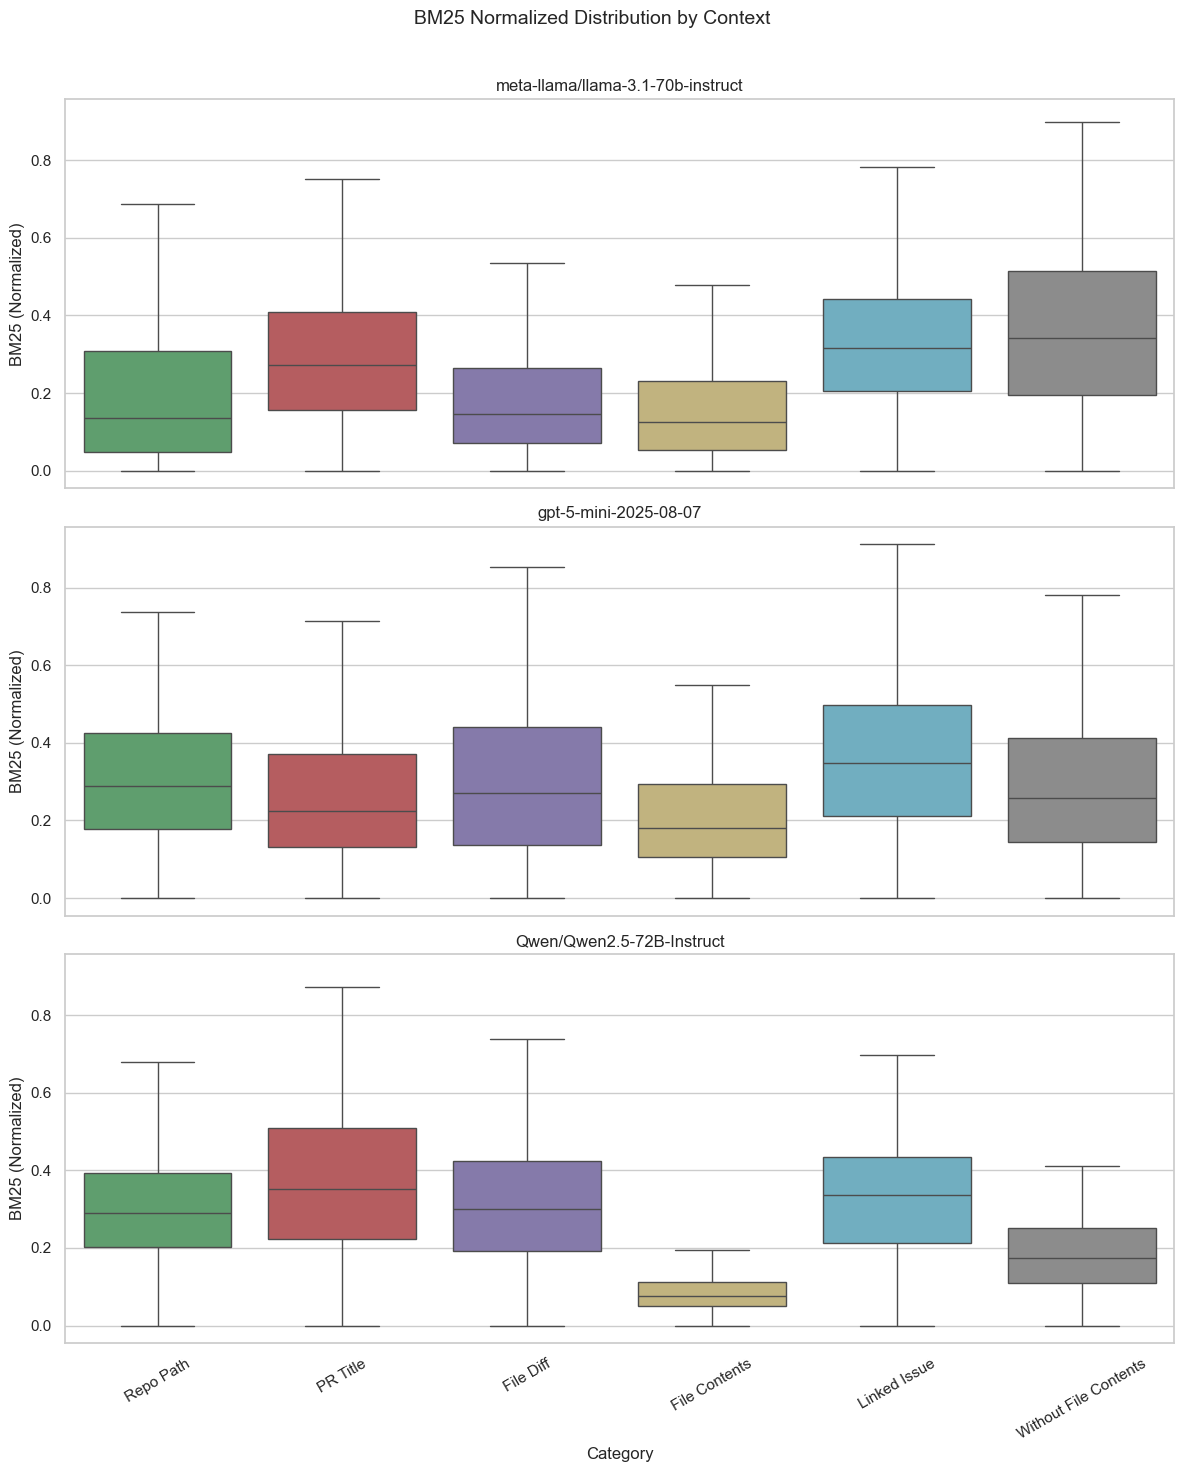

In [11]:
context_order = ['Repo Path', 'PR Title', 'File Diff', 'File Contents', 'Linked Issue', 'Without File Contents']
llm_models = ai_df['model'].dropna().unique().tolist()

palette_map = {
    'Repo Path': '#55A868',
    'PR Title': '#C44E52',
    'File Diff': '#8172B2',
    'File Contents': '#CCB974',
    'Linked Issue': '#64B5CD',
    'Without File Contents': '#8C8C8C'
}

fig, axes = plt.subplots(len(llm_models), 1, figsize=(12, 5 * len(llm_models)), sharex=True, sharey=True)
if len(llm_models) == 1:
    axes = [axes]

for i, model in enumerate(llm_models):
    ax = axes[i]
    ax.set_title(model, fontsize=14)

    panel_df = ai_df[ai_df['model'] == model][['bm25_normalized', 'Context_Name']].dropna().copy()
    panel_df['Category'] = panel_df['Context_Name']

    sns.boxplot(
        data=panel_df,
        x='Category',
        y='bm25_normalized',
        order=context_order,
        hue='Category',
        hue_order=context_order,
        ax=ax,
        palette=palette_map,
        dodge=False,
        legend=False,
        showfliers=False
    )

    ax.set_xlabel('Category' if i == len(llm_models) - 1 else '', fontsize=14)
    ax.set_ylabel('BM25 (Normalized)', fontsize=14)
    ax.tick_params(axis='x', rotation=30, labelsize=12)

plt.tight_layout()
from pathlib import Path
Path('outputs/figures_pdf').mkdir(parents=True, exist_ok=True)
plt.savefig(str(Path('outputs/figures_pdf') / 'bm25.pdf'), bbox_inches='tight', dpi=150)
plt.show()

## 5. Final RQ3 Answer: Human Baseline Comparison (BM25)

This section directly answers the core RQ3 objective using paired AI↔Human BM25 results.

- **Reference**: Original human-written PR descriptions (`n=308`, paired PR set).
- **Candidates**: AI descriptions for each model and context (P-1 ... P-6).
- **Reported**: Mean/Median normalized BM25 per [Model, Context], Cliff's δ vs Human Baseline (normalized BM25), and ranking by highest Median BM25.

In [12]:
# Local helpers (self-contained final section)
def cliffs_delta(lst1, lst2):
    m, n = len(lst1), len(lst2)
    if m == 0 or n == 0:
        return 0.0
    dom = 0
    for x in lst1:
        for y in lst2:
            if x > y:
                dom += 1
            elif x < y:
                dom -= 1
    return dom / (m * n)

def interpret_cliffs_delta(d):
    d = abs(d)
    if d < 0.147:
        return "Negligible"
    elif d < 0.33:
        return "Small"
    elif d < 0.474:
        return "Medium"
    else:
        return "Large"

variation_names = ['Repo Path', 'PR Title', 'File Diff', 'File Contents', 'Linked Issue', 'Without File Contents']

# Human baseline: self-vs-self BM25 is conceptually 1.0 (perfect match after normalization)
# Since raw self-vs-self would always be the max in any corpus, normalized = 1.0
human_baseline_n = len(valid_ids)
human_baseline_vals = np.ones(human_baseline_n)

print(f"Human baseline n = {human_baseline_n}")
print(f"Human BM25 normalized mean = {np.mean(human_baseline_vals):.4f}")
print(f"Human BM25 normalized median = {np.median(human_baseline_vals):.4f}")

# Compare each [Model, Context] against human baseline
rows = []
for model in sorted(ai_df['model'].unique()):
    for ctx in variation_names:
        subset = ai_df[(ai_df['model'] == model) & (ai_df['Context_Name'] == ctx)]
        if subset.empty:
            continue

        bm25_vals = subset['bm25_normalized'].dropna().values
        if len(bm25_vals) == 0:
            continue

        delta = cliffs_delta(bm25_vals.tolist(), human_baseline_vals.tolist())
        rows.append({
            'Model': model,
            'Context': ctx,
            'N_AI': len(bm25_vals),
            'N_Human': human_baseline_n,
            'BM25 Mean (Normalized)': round(float(np.mean(bm25_vals)), 4),
            'BM25 Median (Normalized)': round(float(np.median(bm25_vals)), 4),
            "Cliff's Delta (BM25 AI vs Human)": round(float(delta), 4),
            'Effect Size': interpret_cliffs_delta(delta)
        })

bm25_cmp_df = pd.DataFrame(rows)
bm25_cmp_df = bm25_cmp_df.sort_values(['Model', 'BM25 Median (Normalized)', 'BM25 Mean (Normalized)'], ascending=[True, False, False])
bm25_cmp_df['Most Human Rank (within model)'] = bm25_cmp_df.groupby('Model')['BM25 Median (Normalized)'].rank(method='dense', ascending=False).astype(int)

print('\n[Model, Context] vs Human baseline (sorted by highest BM25 Median):')
display(bm25_cmp_df)

best_context_per_model_df = (
    bm25_cmp_df.sort_values(['Model', 'BM25 Median (Normalized)', 'BM25 Mean (Normalized)'], ascending=[True, False, False])
    .groupby('Model', as_index=False)
    .first()[['Model', 'Context', 'BM25 Mean (Normalized)', 'BM25 Median (Normalized)', "Cliff's Delta (BM25 AI vs Human)", 'Effect Size', 'Most Human Rank (within model)']]
    .sort_values('Model')
)

print('\nBest context per model (highest BM25 Median):')
display(best_context_per_model_df)

os.makedirs('outputs', exist_ok=True)
bm25_cmp_df.to_csv('outputs/rq3_bm25_ai_vs_human_baseline.csv', index=False)
best_context_per_model_df.to_csv('outputs/rq3_bm25_most_human_context_per_model.csv', index=False)
print('Saved: outputs/rq3_bm25_ai_vs_human_baseline.csv')
print('Saved: outputs/rq3_bm25_most_human_context_per_model.csv')

Human baseline n = 308
Human BM25 normalized mean = 1.0000
Human BM25 normalized median = 1.0000

[Model, Context] vs Human baseline (sorted by highest BM25 Median):


,Model,Context,N_AI,N_Human,BM25 Mean (Normalized),BM25 Median (Normalized),Cliff's Delta (BM25 AI vs Human),Effect Size,Most Human Rank (within model)
1,Qwen/Qwen2.5-72B-Instruct,PR Title,308,308,0.3634,0.3510,-0.9968,Large,1
4,Qwen/Qwen2.5-72B-Instruct,Linked Issue,308,308,0.3360,0.3366,-0.9968,Large,2
2,Qwen/Qwen2.5-72B-Instruct,File Diff,308,308,0.3164,0.2994,-0.9968,Large,3
0,Qwen/Qwen2.5-72B-Instruct,Repo Path,308,308,0.3095,0.2900,-0.9968,Large,4
5,Qwen/Qwen2.5-72B-Instruct,Without File Contents,308,308,0.1881,0.1731,-0.9968,Large,5
3,Qwen/Qwen2.5-72B-Instruct,File Contents,302,308,0.0850,0.0770,-0.9967,Large,6
10,gpt-5-mini-2025-08-07,Linked Issue,308,308,0.3690,0.3490,-0.9968,Large,1
6,gpt-5-mini-2025-08-07,Repo Path,308,308,0.3122,0.2879,-0.9968,Large,2
8,gpt-5-mini-2025-08-07,File Diff,308,308,0.3090,0.2702,-0.9968,Large,3
11,gpt-5-mini-2025-08-07,Without File Contents,308,308,0.2858,0.2591,-0.9968,Large,4



Best context per model (highest BM25 Median):


,Model,Context,BM25 Mean (Normalized),BM25 Median (Normalized),Cliff's Delta (BM25 AI vs Human),Effect Size,Most Human Rank (within model)
0,Qwen/Qwen2.5-72B-Instruct,PR Title,0.3634,0.3510,-0.9968,Large,1
1,gpt-5-mini-2025-08-07,Linked Issue,0.3690,0.3490,-0.9968,Large,1
2,meta-llama/llama-3.1-70b-instruct,Without File Contents,0.3566,0.3413,-0.9968,Large,1


Saved: outputs/rq3_bm25_ai_vs_human_baseline.csv
Saved: outputs/rq3_bm25_most_human_context_per_model.csv
